## Classification

class
0    60.595523
1    39.404477
Name: proportion, dtype: float64


/var/folders/b3/2tbk3zy55bb28myr00ztdbw00000gp/T/ipykernel_99211/1084457471.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['capital_run_length_average'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))


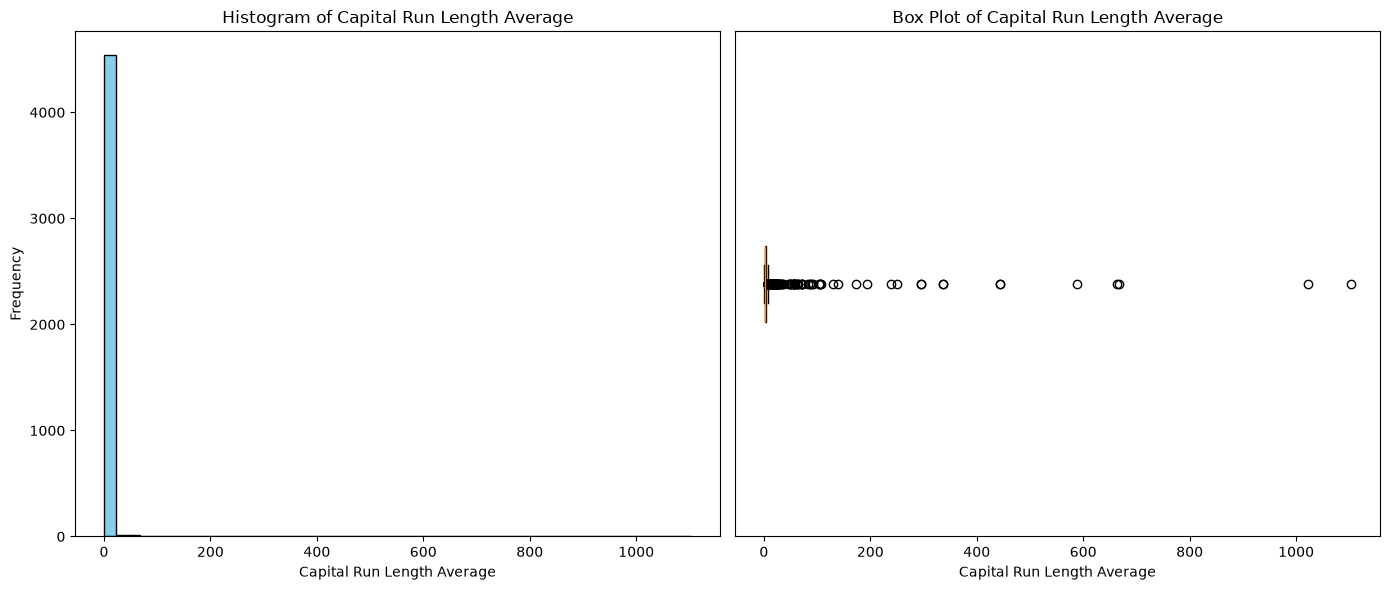

[1 1 0 1 0 0 0 1 0 0]
Accuracy: 0.92


In [12]:
#from google.colab import drive
#drive.mount('/content/gdrive', force_remount=True)

import pandas as pd

df = pd.read_csv('spambase_csv.csv', encoding='latin1')
df.columns = df.columns.str.strip() # remove spacing
print(df['class'].value_counts(normalize=True) * 100)

#print(df.head())

#print(df.isnull().sum()) # no missing values
#print(df.info())
# print(df['class'].value_counts()) # distribution of spam and not spam
#print(df.describe())

### The distribution is imbalanced

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
plt.hist(df['capital_run_length_average'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Capital Run Length Average')
plt.xlabel('Capital Run Length Average')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
plt.boxplot(df['capital_run_length_average'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Box Plot of Capital Run Length Average')
plt.xlabel('Capital Run Length Average')
plt.yticks([]) # Hide y-axis ticks for better visualization

plt.tight_layout()
plt.show()

# splitting data into training and testing

X = df.drop('class', axis=1) # features
y = df['class'] # target is the answer column

# splitting data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y #keeps the same class ratio, no impalancing
)


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)
lr_model.fit(X_train_scaled, y_train)

# prediction
y_pred = lr_model.predict(X_test_scaled)

print(y_pred[:10])

# accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")








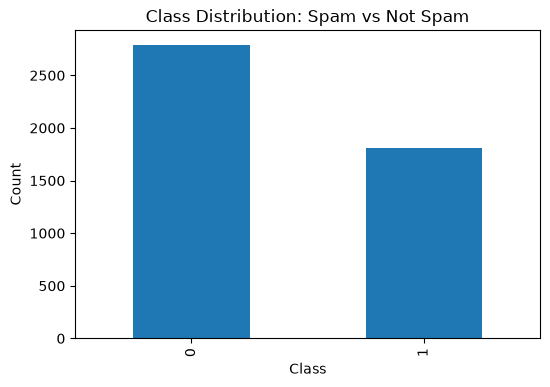

In [13]:
plt.figure(figsize=(6, 4))
df['class'].value_counts().plot(kind='bar')
plt.title('Class Distribution: Spam vs Not Spam')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

/var/folders/b3/2tbk3zy55bb28myr00ztdbw00000gp/T/ipykernel_99211/2941665401.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['word_freq_remove'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))


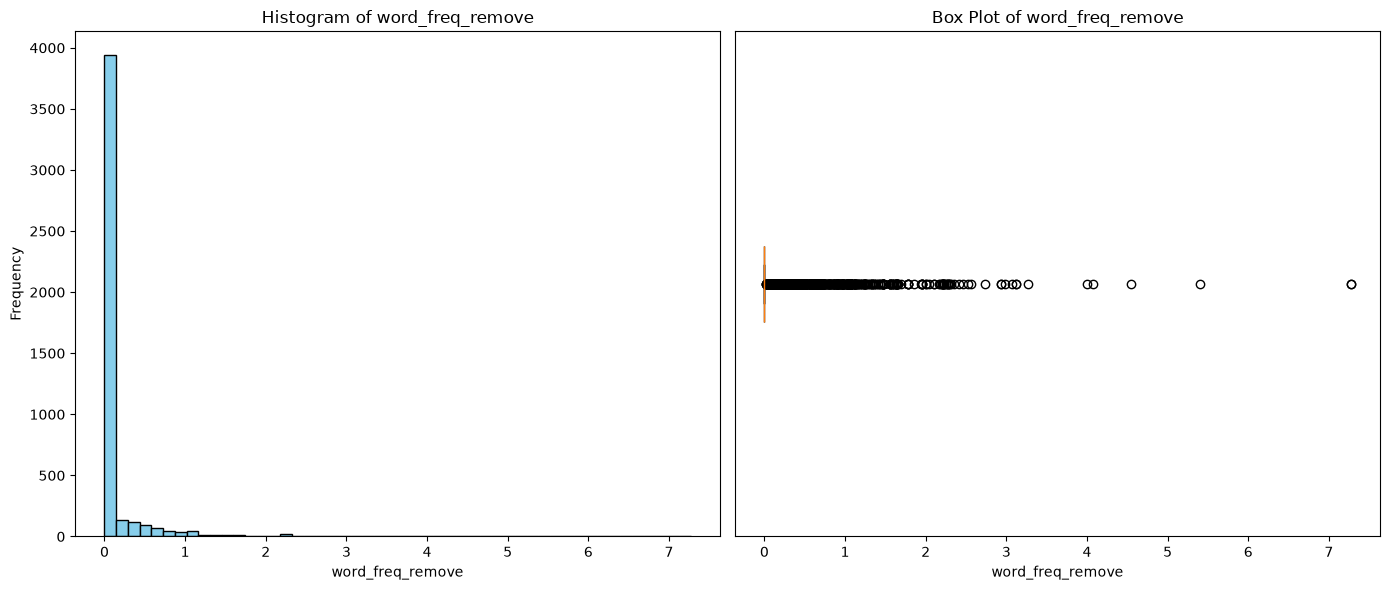

In [14]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
plt.hist(df['word_freq_remove'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of word_freq_remove')
plt.xlabel('word_freq_remove')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
plt.boxplot(df['word_freq_remove'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Box Plot of word_freq_remove')
plt.xlabel('word_freq_remove')
plt.yticks([]) # Hide y-axis ticks for better visualization

plt.tight_layout()
plt.show()

In [15]:
df.columns

Index(['word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d',
       'word_freq_our', 'word_freq_over', 'word_freq_remove',
       'word_freq_internet', 'word_freq_order', 'word_freq_mail',
       'word_freq_receive', 'word_freq_will', 'word_freq_people',
       'word_freq_report', 'word_freq_addresses', 'word_freq_free',
       'word_freq_business', 'word_freq_email', 'word_freq_you',
       'word_freq_credit', 'word_freq_your', 'word_freq_font', 'word_freq_000',
       'word_freq_money', 'word_freq_hp', 'word_freq_hpl', 'word_freq_george',
       'word_freq_650', 'word_freq_lab', 'word_freq_labs', 'word_freq_telnet',
       'word_freq_857', 'word_freq_data', 'word_freq_415', 'word_freq_85',
       'word_freq_technology', 'word_freq_1999', 'word_freq_parts',
       'word_freq_pm', 'word_freq_direct', 'word_freq_cs', 'word_freq_meeting',
       'word_freq_original', 'word_freq_project', 'word_freq_re',
       'word_freq_edu', 'word_freq_table', 'word_freq_conference',


[1 1 0 1 0 0 0 1 0 1]
Random Forest Accuracy: 0.94
                       Feature  Importance
51               char_freq_%21    0.122839
52               char_freq_%24    0.089677
6             word_freq_remove    0.071987
55  capital_run_length_longest    0.062069
15              word_freq_free    0.061747
54  capital_run_length_average    0.057835
56    capital_run_length_total    0.056207
24                word_freq_hp    0.054394
20              word_freq_your    0.050936
26            word_freq_george    0.031504
18               word_freq_you    0.030121
4                word_freq_our    0.025981
23             word_freq_money    0.025943
25               word_freq_hpl    0.022873
22               word_freq_000    0.021639
45               word_freq_edu    0.021403
36              word_freq_1999    0.015112
11              word_freq_will    0.012337
7           word_freq_internet    0.012333
49               char_freq_%28    0.011777


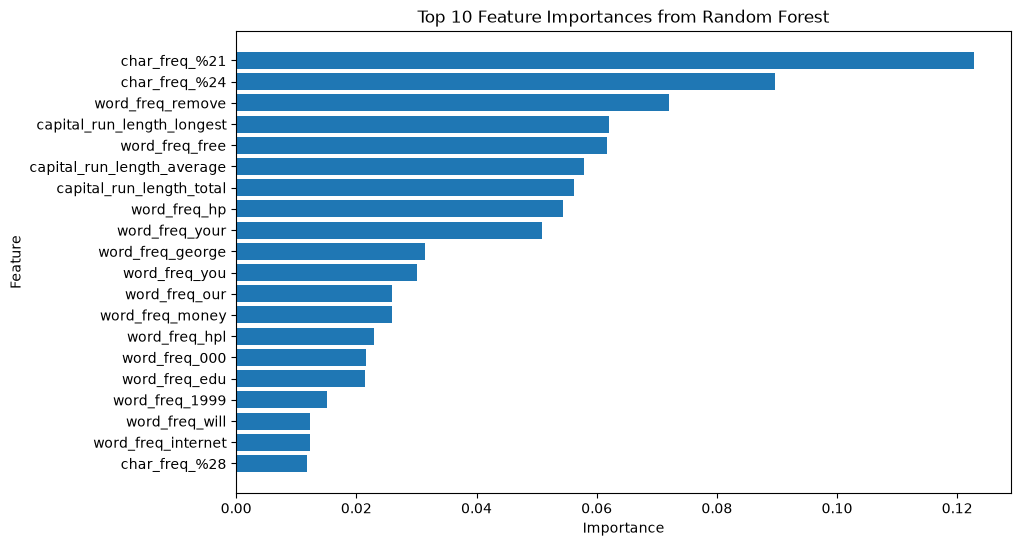

In [16]:
###Random Forest classification

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train) # train the model with training data

y_pred_rf = rf_model.predict(X_test)
print(y_pred_rf[:10])

accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf:.2f}")

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# this tells us what features were useful in training
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20)) # print top 10

#plotting
import matplotlib.pyplot as plt

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances from Random Forest')
plt.gca().invert_yaxis()
plt.show()

Logistic Regression Metrics:
Accuracy: 0.92
Precision: 0.89
Recall: 0.91
F1 Score: 0.90

Random Forest Metrics:
Accuracy: 0.94
Precision: 0.93
Recall: 0.93
F1 Score: 0.93


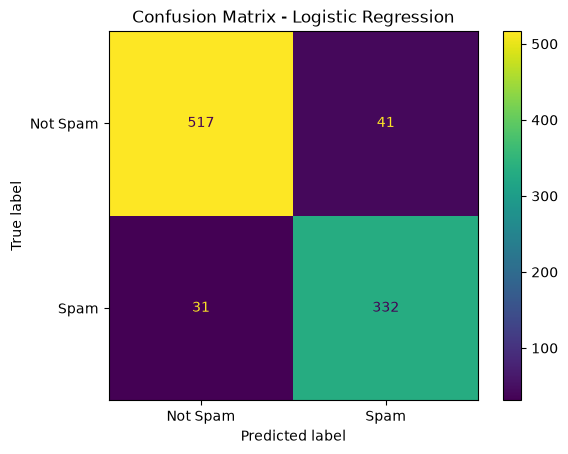


Logistic Regression Confusion Matrix:
[[517  41]
 [ 31 332]]


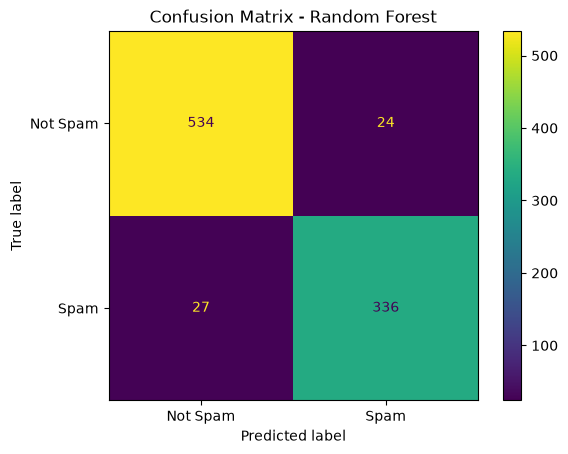


Random Forest Confusion Matrix:
[[534  24]
 [ 27 336]]

Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.921824   0.890080  0.914601  0.902174
1        Random Forest  0.944625   0.933333  0.925620  0.929461


In [17]:
### Model evaluation and comparison
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# logistic regression
l_acc = accuracy_score(y_test, y_pred)
l_prec = precision_score(y_test, y_pred)
l_rec = recall_score(y_test, y_pred)
l_f1 = f1_score(y_test, y_pred)

print("Logistic Regression Metrics:")
print(f"Accuracy: {l_acc:.2f}")
print(f"Precision: {l_prec:.2f}")
print(f"Recall: {l_rec:.2f}")
print(f"F1 Score: {l_f1:.2f}")

# random forest classification
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf)
rf_rec = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("\nRandom Forest Metrics:")
print(f"Accuracy: {rf_acc:.2f}")
print(f"Precision: {rf_prec:.2f}")
print(f"Recall: {rf_rec:.2f}")
print(f"F1 Score: {rf_f1:.2f}")

#Confusion matrix
cm_lr = confusion_matrix(y_test, y_pred)
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Not Spam', 'Spam']
)
disp_lr.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)


cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Not Spam', 'Spam']
)
disp_rf.plot()
plt.title('Confusion Matrix - Random Forest')
plt.show()


print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

# comparison
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [l_acc, rf_acc],
    'Precision': [l_prec, rf_prec],
    'Recall': [l_rec, rf_rec],
    'F1 Score': [l_f1, rf_f1]
})

print("\nModel Comparison:")
print(comparison)

In [18]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear')

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print(y_pred_svm[:10])

accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy: {accuracy_svm:.2f}")

[1 1 0 1 0 0 0 1 0 0]
SVM Accuracy: 0.93


TARGET
0    98.320999
1     1.679001
Name: proportion, dtype: float64


/var/folders/b3/2tbk3zy55bb28myr00ztdbw00000gp/T/ipykernel_4712/560214124.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns


Before SMOTE:
TARGET
0    19769
1      338
Name: count, dtype: int64
After SMOTE:
TARGET
0    19769
1     4942
Name: count, dtype: int64
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4943
           1       0.87      0.69      0.77        84

    accuracy                           0.99      5027
   macro avg       0.93      0.84      0.88      5027
weighted avg       0.99      0.99      0.99      5027



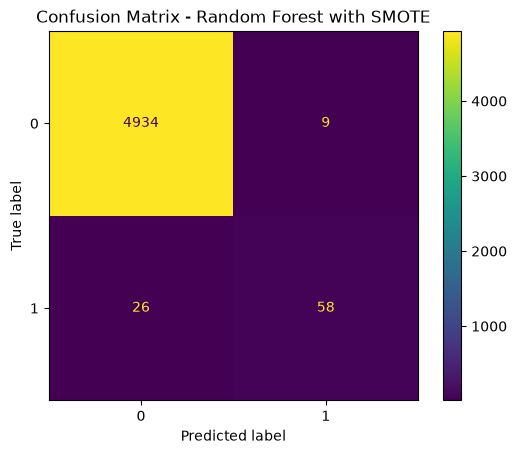

In [1]:
#from google.colab import drive
#drive.mount('/content/gdrive', force_remount=True)

import pandas as pd

df = pd.read_csv('credit_dataset.csv', encoding='latin1')
df.columns = df.columns.str.strip() # remove spacing
print(df['TARGET'].value_counts(normalize=True) * 100)

#print(df.head())
X = df.drop('TARGET', axis=1) # features
y = df['TARGET'] # target is the answer column

# splitting data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y #keeps the same class ratio, no impalancing
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy=0.25,
    random_state=42
)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("After SMOTE:")
print(y_train_smote.value_counts())

# fit and predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_smote, y_train_smote)

y_pred_rf = rf_model.predict(X_test_processed)

print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Random Forest with SMOTE")
plt.show()


        Before SMOTE  After SMOTE
TARGET                           
0              19769        19769
1                338         4942


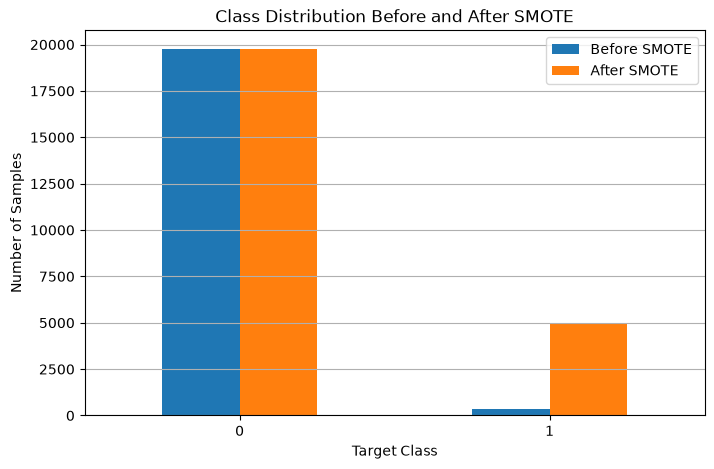

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

before_counts = y_train.value_counts().sort_index()
after_counts = y_train_smote.value_counts().sort_index()

imbalance_df = pd.DataFrame({
    'Before SMOTE': before_counts,
    'After SMOTE': after_counts
}).fillna(0)

print(imbalance_df)

imbalance_df.plot(kind='bar', figsize=(8, 5))

plt.title('Class Distribution Before and After SMOTE')
plt.xlabel('Target Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()